# LAB 05 — Sequence Models: RNN, LSTM and GRU (IMDb)

**Dataset:** IMDb (`stanfordnlp/imdb`), sentiment positive / negative. Split giống LAB 04: train gốc (bỏ review trùng) chia stratified 80/20 → train / validation (seed 42); test = 25 000 review của tập test chính thức, chỉ dùng để báo cáo.

**Điều kiện chung cho mọi recurrent model:** vocabulary 25 000 từ phổ biến nhất trong train (+ `<pad>` = 0, `<unk>` = 1), embedding 100 chiều (train từ đầu), hidden 128, 1 layer, một chiều; batch 64; Adam lr = 1e-3; 6 epochs; gradient clipping 1.0; dropout 0.3 trước lớp Linear; dùng hidden state **cuối cùng thật** (packed sequence, không đọc qua padding); chọn epoch có validation loss thấp nhất để đánh giá test.

In [1]:
import os, warnings
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"; os.environ["HF_HUB_VERBOSITY"] = "error"
warnings.filterwarnings("ignore")
import re, time, copy, random
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from collections import Counter
import torch, torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
import rnn_cell

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")

ds = load_dataset("stanfordnlp/imdb")
train_raw, test_df = ds["train"].to_pandas(), ds["test"].to_pandas()
_BR, _NON, _SP = re.compile(r"<br\s*/?>", re.I), re.compile(r"[^a-z0-9'\s]"), re.compile(r"\s+")
def clean_text(t):
    return _SP.sub(" ", _NON.sub(" ", _BR.sub(" ", str(t).lower()))).strip()
def tokenize(t):
    return clean_text(t).split()

Device: cuda NVIDIA GeForce RTX 3050 Laptop GPU


## Experiment 1 — Dataset inspection

,samples,classes,negative,positive,min len,median len,mean len,max len,duplicate texts,missing text,missing label
split,,,,,,,,,,,
train (gốc),25000,2,12500,12500,10,174.0,233.7,2473,96,0,0
test,25000,2,12500,12500,6,172.0,228.4,2246,199,0,0


Sau khi bỏ 96 review trùng: train 19923 / validation 4981 / test 25000
Review xuất hiện ở cả train và test: 123


Percentile độ dài (train): {25: 127, 50: 174, 75: 284, 90: 457, 95: 596}
max_length =  30:   0.2% review không bị cắt |  12.8% token được giữ lại
max_length =  50:   2.4% review không bị cắt |  21.3% token được giữ lại
max_length = 100:  12.2% review không bị cắt |  41.2% token được giữ lại
max_length = 200:  58.5% review không bị cắt |  68.2% token được giữ lại
max_length = 400:  86.6% review không bị cắt |  89.0% token được giữ lại


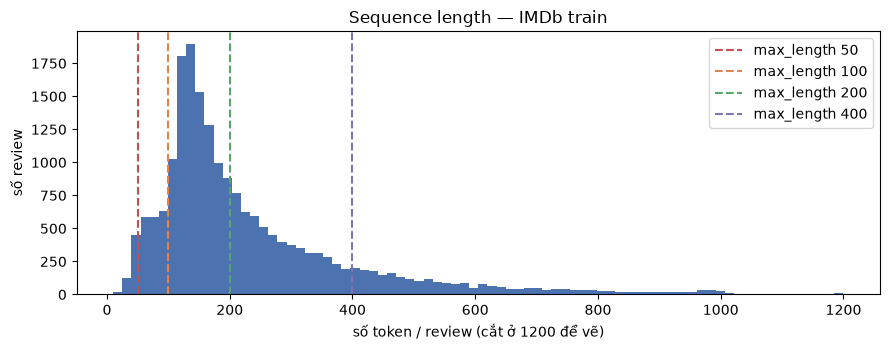

In [2]:
rows = []
for name, d in [("train (gốc)", train_raw), ("test", test_df)]:
    lens = d.text.map(lambda t: len(tokenize(t)))
    rows.append({"split": name, "samples": len(d), "classes": d.label.nunique(), "negative": (d.label == 0).sum(), "positive": (d.label == 1).sum(),
                 "min len": lens.min(), "median len": lens.median(), "mean len": round(lens.mean(), 1), "max len": lens.max(),
                 "duplicate texts": d.text.duplicated().sum(), "missing text": d.text.isna().sum() + (d.text.str.strip() == "").sum(),
                 "missing label": d.label.isna().sum()})
display(pd.DataFrame(rows).set_index("split"))
train_dedup = train_raw.drop_duplicates("text").reset_index(drop=True)
tr_df, va_df = train_test_split(train_dedup, test_size=0.2, stratify=train_dedup.label, random_state=SEED)
tr_df, va_df = tr_df.reset_index(drop=True), va_df.reset_index(drop=True)
print(f"Sau khi bỏ {len(train_raw) - len(train_dedup)} review trùng: train {len(tr_df)} / validation {len(va_df)} / test {len(test_df)}")
overlap = len(set(train_dedup.text) & set(test_df.text))
print(f"Review xuất hiện ở cả train và test: {overlap}")

tok = {k: [tokenize(t) for t in d.text] for k, d in [("train", tr_df), ("val", va_df), ("test", test_df)]}
y = {"train": tr_df.label.values, "val": va_df.label.values, "test": test_df.label.values}
L = np.array([len(t) for t in tok["train"]])
pct = {p: int(np.percentile(L, p)) for p in (25, 50, 75, 90, 95)}
print("Percentile độ dài (train):", pct)
for ml in (30, 50, 100, 200, 400):
    print(f"max_length = {ml:3d}: {np.mean(L <= ml):6.1%} review không bị cắt | {np.minimum(L, ml).sum() / L.sum():6.1%} token được giữ lại")
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(np.minimum(L, 1200), bins=80, color="#4c72b0")
for ml, c in [(50, "#c44e52"), (100, "#dd8452"), (200, "#55a868"), (400, "#8172b2")]:
    ax.axvline(ml, color=c, ls="--", label=f"max_length {ml}")
ax.set_xlabel("số token / review (cắt ở 1200 để vẽ)"); ax.set_ylabel("số review"); ax.set_title("Sequence length — IMDb train"); ax.legend()
plt.tight_layout(); plt.savefig("sequence_length.png", dpi=150); plt.show()

## Tokenization, vocabulary, padding / truncation

In [3]:
counts = Counter(w for t in tok["train"] for w in t)
itos = ["<pad>", "<unk>"] + [w for w, _ in counts.most_common(25000)]
stoi = {w: i for i, w in enumerate(itos)}
PAD, UNK = 0, 1
def encode(tokens, max_len, mode="head"):
    ids = [stoi.get(w, UNK) for w in tokens] or [UNK]
    return ids[:max_len] if mode == "head" else ids[-max_len:]
def to_tensor(tok_lists, max_len, mode="head"):
    seqs = [encode(t, max_len, mode) for t in tok_lists]
    X = np.zeros((len(seqs), max_len), dtype=np.int64)           # padding = 0 ở cuối
    for i, s in enumerate(seqs):
        X[i, :len(s)] = s
    return torch.from_numpy(X), torch.tensor([len(s) for s in seqs])
ex = "I really like this movie"
print(f"Vocabulary: {len(itos):,} (25 000 từ + <pad> + <unk>); phủ {sum(counts[w] for w in itos[2:]) / sum(counts.values()):.1%} token train")
print(f"{ex!r} → {encode(tokenize(ex), 8)} → padded: {to_tensor([tokenize(ex)], 8)[0][0].tolist()}")
print("UNK rate validation:", round(np.mean([stoi.get(w, UNK) == UNK for t in tok["val"] for w in t]), 4))

Vocabulary: 25,002 (25 000 từ + <pad> + <unk>); phủ 97.9% token train
'I really like this movie' → [10, 63, 37, 11, 17] → padded: [10, 63, 37, 11, 17, 0, 0, 0]


UNK rate validation: 0.0246


## Core implementation — Simple RNN cell (NumPy) vs PyTorch

In [4]:
rnn_cell.run_tests()
c = rnn_cell.SimpleRNNCell(2, 2)
c.W_xh, c.W_hh, c.b_h = np.array([[0.5, 0.2], [0.1, 0.4]]), np.array([[0.3, 0.1], [0.2, 0.5]]), np.zeros(2)
h, a = c.forward([1, 0], [0.5, 0.2])
print("Bài 1: a_t =", a.round(4), "→ h_t = tanh(a_t) =", h.round(4))
print("max |h_numpy − h_torch.nn.RNNCell| trên sequence 6 bước:", rnn_cell.check_against_torch())

PASS  test_bai1_hand_calculation
PASS  test_hidden_state_depends_on_order
PASS  test_against_torch
3/3 tests passed
Bài 1: a_t = [0.67 0.3 ] → h_t = tanh(a_t) = [0.585  0.2913]
max |h_numpy − h_torch.nn.RNNCell| trên sequence 6 bước: 1.1102230246251565e-16


## Experiment 3 — Baseline: TF-IDF + Logistic Regression (từ LAB 04)

In [5]:
def metrics(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="binary")
    return {"accuracy": accuracy_score(y_true, y_pred), "precision": p, "recall": r, "f1": f}

results, curves, store = [], {}, {}
def tfidf_baseline(name, max_len=None):
    cut = (lambda ts: [" ".join(t[:max_len]) for t in ts]) if max_len else (lambda ts: [" ".join(t) for t in ts])
    t0 = time.time()
    vec = TfidfVectorizer(min_df=2, sublinear_tf=True)
    Xtr = vec.fit_transform(cut(tok["train"])); Xva = vec.transform(cut(tok["val"])); Xte = vec.transform(cut(tok["test"]))
    best = max((LogisticRegression(C=C, max_iter=2000).fit(Xtr, y["train"]) for C in (0.5, 1, 2, 4)),
               key=lambda m: metrics(y["val"], m.predict(Xva))["f1"])
    dt = time.time() - t0
    prob = best.predict_proba(Xte)[:, 1]
    store[name] = {"prob": prob, "vec": vec, "clf": best}
    results.append({"model": name, "representation": "TF-IDF (unigram)", "max_length": max_len or "full", "params": Xtr.shape[1] + 1,
                    "epochs": "-", "best epoch": "-", "train time (s)": dt, **metrics(y["test"], prob > 0.5)})
tfidf_baseline("Logistic Regression")
tfidf_baseline("Logistic Regression (200 tokens đầu)", max_len=200)
display(pd.DataFrame(results).round(4))

,model,representation,max_length,params,epochs,best epoch,train time (s),accuracy,precision,recall,f1
0,Logistic Regression,TF-IDF (unigram),full,40791,-,-,7.1463,0.8882,0.8881,0.8885,0.8883
1,Logistic Regression (200 tokens đầu),TF-IDF (unigram),200,34395,-,-,5.7810,0.8621,0.8634,0.8603,0.8619


## Experiment 4 — RNN vs LSTM vs GRU

In [6]:
class SeqClassifier(nn.Module):
    def __init__(self, rnn_type, vocab_size=len(itos), emb_dim=100, hidden=128, dropout=0.3):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD)
        self.rnn = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[rnn_type](emb_dim, hidden, batch_first=True)
        self.drop = nn.Dropout(dropout)
        self.out = nn.Linear(hidden, 1)
        self.rnn_type = rnn_type

    def forward(self, x, lengths, embedded=None):
        e = self.emb(x) if embedded is None else embedded
        packed = pack_padded_sequence(e, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, h = self.rnn(packed)
        h = h[0] if self.rnn_type == "LSTM" else h                 # LSTM trả về (h_T, c_T)
        return self.out(self.drop(h[-1])).squeeze(-1)

def batches(X, lens, yv, bs, shuffle):
    idx = torch.randperm(len(X)) if shuffle else torch.arange(len(X))
    for i in range(0, len(X), bs):
        j = idx[i:i + bs]
        yield X[j].to(device), lens[j].to(device), (torch.as_tensor(yv[j.numpy()], dtype=torch.float32).to(device) if yv is not None else None)

@torch.no_grad()
def predict_logits(model, X, lens, bs=512):
    model.eval()
    return torch.cat([model(xb, lb).float().cpu() for xb, lb, _ in batches(X, lens, None, bs, False)])

def predict_proba(model, X, lens, bs=512):
    return torch.sigmoid(predict_logits(model, X, lens, bs)).numpy()

def run(name, rnn_type, max_len=200, mode="head", epochs=6, bs=64, lr=1e-3, record=True):
    set_seed()
    data = {k: to_tensor(tok[k], max_len, mode) for k in ("train", "val", "test")}
    model = SeqClassifier(rnn_type).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr); lossf = nn.BCEWithLogitsLoss()
    hist, best, best_state = [], (np.inf, 0), None
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize()
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train(); tot, n = 0.0, 0
        for xb, lb, yb in batches(*data["train"], y["train"], bs, True):
            opt.zero_grad(); loss = lossf(model(xb, lb), yb); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            tot += loss.item() * len(yb); n += len(yb)
        logits = predict_logits(model, *data["val"]); pv = torch.sigmoid(logits).numpy()
        vloss = float(nn.functional.binary_cross_entropy_with_logits(logits, torch.tensor(y["val"], dtype=torch.float32)))
        hist.append({"epoch": ep, "train loss": tot / n, "val loss": vloss, "val acc": accuracy_score(y["val"], pv > 0.5)})
        if vloss < best[0]:
            best, best_state = (vloss, ep), copy.deepcopy(model.state_dict())
    if device.type == "cuda":
        torch.cuda.synchronize()
    dt = time.time() - t0
    mem = torch.cuda.max_memory_allocated() / 2**20 if device.type == "cuda" else np.nan
    model.load_state_dict(best_state)
    prob = predict_proba(model, *data["test"])
    row = {"model": name, "representation": "Embedding (train từ đầu)", "max_length": max_len, "truncation": mode,
           "params": sum(p.numel() for p in model.parameters()), "epochs": epochs, "best epoch": best[1], "train time (s)": dt,
           "time / epoch (s)": dt / epochs, "peak GPU mem (MB)": mem, "best val loss": best[0], **metrics(y["test"], prob > 0.5)}
    if record:
        results.append(row)
    curves[name] = pd.DataFrame(hist); store[name] = {"prob": prob, "model": model, "max_len": max_len, "mode": mode}
    print(f"{name:28s} | best epoch {best[1]} | val loss {best[0]:.4f} | test acc {row['accuracy']:.4f} F1 {row['f1']:.4f} | {dt:.1f}s")
    return row

for arch in ("RNN", "LSTM", "GRU"):
    run(arch, arch, max_len=200)
cols = ["model", "params", "train time (s)", "best epoch", "accuracy", "precision", "recall", "f1"]
exp4 = pd.DataFrame(results)[cols]
display(exp4.round(4))

RNN                          | best epoch 6 | val loss 0.5792 | test acc 0.7408 F1 0.7482 | 37.3s


LSTM                         | best epoch 4 | val loss 0.4309 | test acc 0.8156 F1 0.8117 | 42.3s


GRU                          | best epoch 3 | val loss 0.3822 | test acc 0.8322 F1 0.8219 | 40.4s


,model,params,train time (s),best epoch,accuracy,precision,recall,f1
0,Logistic Regression,40791,7.1463,-,0.8882,0.8881,0.8885,0.8883
1,Logistic Regression (200 tokens đầu),34395,5.7810,-,0.8621,0.8634,0.8603,0.8619
2,RNN,2529769,37.3231,6,0.7408,0.7274,0.7702,0.7482
3,LSTM,2618089,42.3080,4,0.8156,0.8291,0.7950,0.8117
4,GRU,2588649,40.3797,3,0.8322,0.8756,0.7743,0.8219


### Learning curves

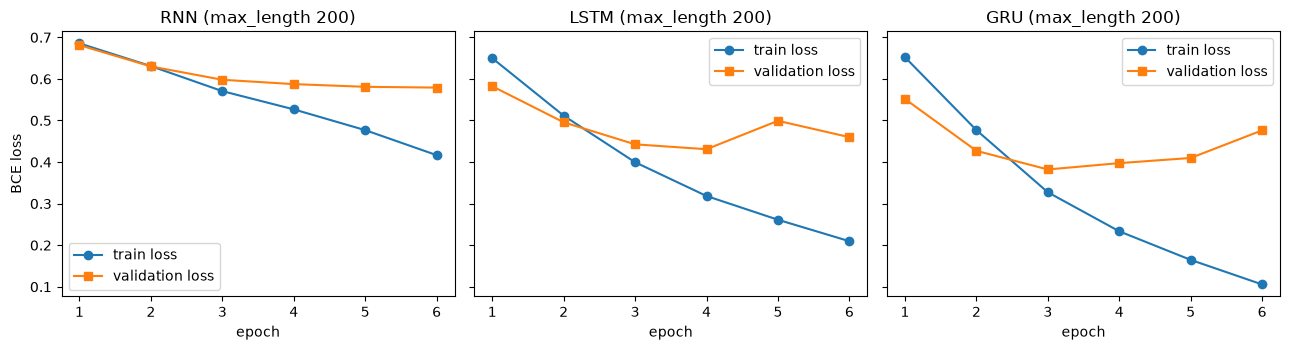

RNN                        LSTM                         GRU  \
      train loss val loss val acc train loss val loss val acc train loss   
epoch                                                                      
1         0.6855   0.6813  0.5786     0.6500   0.5824  0.6930     0.6523   
2         0.6309   0.6301  0.6529     0.5117   0.4957  0.7790     0.4769   
3         0.5707   0.5980  0.7077     0.3996   0.4426  0.8029     0.3273   
4         0.5268   0.5875  0.7051     0.3184   0.4309  0.8155     0.2334   
5         0.4768   0.5811  0.7539     0.2612   0.4993  0.7988     0.1646   
6         0.4167   0.5792  0.7446     0.2096   0.4599  0.8203     0.1055   

                        
      val loss val acc  
epoch                   
1       0.5518  0.7286  
2       0.4270  0.8079  
3       0.3822  0.8374  
4       0.3974  0.8352  
5       0.4098  0.8550  
6       0.4763  0.8518

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for a_, arch in zip(ax, ("RNN", "LSTM", "GRU")):
    cv = curves[arch]
    a_.plot(cv.epoch, cv["train loss"], marker="o", label="train loss"); a_.plot(cv.epoch, cv["val loss"], marker="s", label="validation loss")
    a_.set_title(f"{arch} (max_length 200)"); a_.set_xlabel("epoch"); a_.legend()
ax[0].set_ylabel("BCE loss")
plt.tight_layout(); plt.savefig("learning_curves.png", dpi=150); plt.show()
display(pd.concat({a: curves[a].set_index("epoch") for a in ("RNN", "LSTM", "GRU")}, axis=1).round(4))

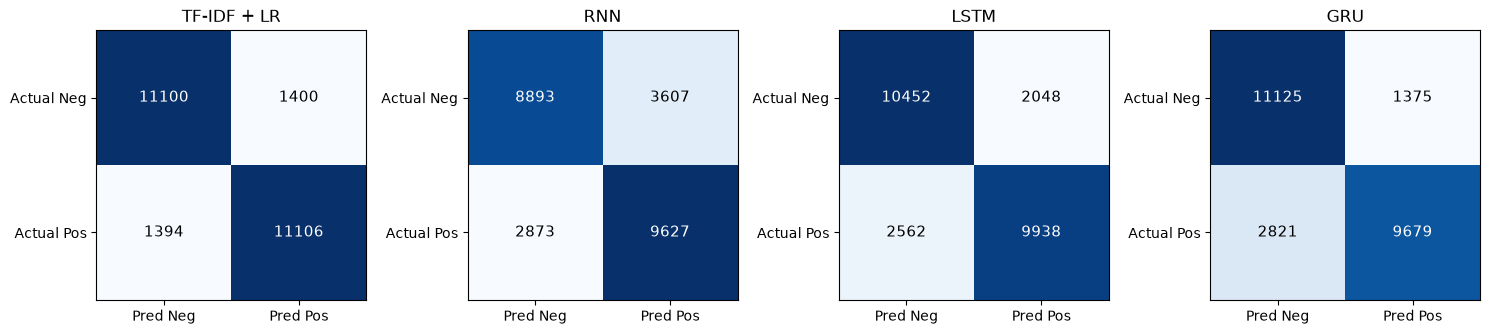

In [8]:
fig, ax = plt.subplots(1, 4, figsize=(15, 3.4))
for a_, name in zip(ax, ["Logistic Regression", "RNN", "LSTM", "GRU"]):
    cm = confusion_matrix(y["test"], store[name]["prob"] > 0.5)
    a_.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        a_.text(j, i, f"{v}", ha="center", va="center", color="white" if v > cm.max() / 2 else "black", fontsize=11)
    a_.set_xticks([0, 1], ["Pred Neg", "Pred Pos"]); a_.set_yticks([0, 1], ["Actual Neg", "Actual Pos"])
    a_.set_title(name if name != "Logistic Regression" else "TF-IDF + LR")
plt.tight_layout(); plt.savefig("confusion_matrix.png", dpi=150); plt.show()

## Experiment 5 — Sequence length (max_length 50 / 100 / 200 / 400), architecture cố định: LSTM
Thêm: **head** (giữ 100 token đầu) vs **tail** (giữ 100 token cuối) truncation.

LSTM len 50                  | best epoch 4 | val loss 0.5123 | test acc 0.7457 F1 0.7515 | 17.5s


LSTM len 100                 | best epoch 5 | val loss 0.4586 | test acc 0.7901 F1 0.7853 | 25.6s


LSTM len 400                 | best epoch 4 | val loss 0.3735 | test acc 0.8492 F1 0.8468 | 69.9s


LSTM len 100 (tail)          | best epoch 3 | val loss 0.3860 | test acc 0.8288 F1 0.8276 | 24.7s


,% tokens retained (val),% reviews not truncated,train time (s),peak GPU mem (MB),best val loss,test accuracy,test F1
max_length,,,,,,,
50,0.2114,0.0233,17.5315,220.0962,0.5123,0.7457,0.7515
100,0.4090,0.1162,25.5582,318.5342,0.4586,0.7901,0.7853
200,0.6795,0.5856,42.3080,373.9956,0.4309,0.8156,0.8117
400,0.8862,0.8651,69.9353,568.3882,0.3735,0.8492,0.8468


LSTM len 100: head F1 = 0.7853 | tail F1 = 0.8276


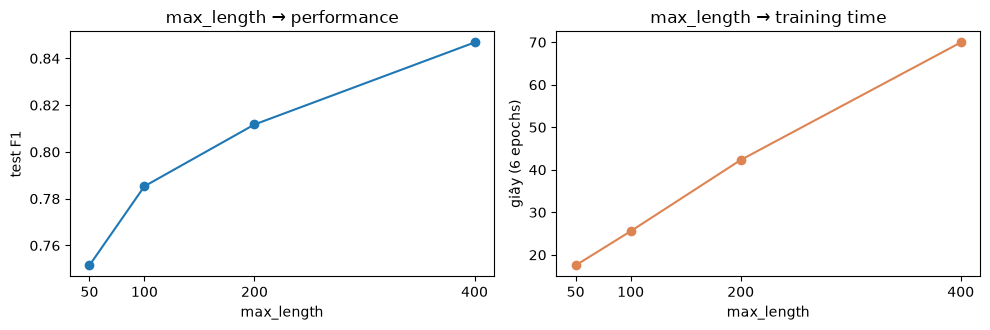

In [9]:
len_rows = []
for ml in (50, 100, 200, 400):
    r = run(f"LSTM len {ml}", "LSTM", max_len=ml) if ml != 200 else results[[x["model"] for x in results].index("LSTM")]
    len_rows.append({"max_length": ml, "% tokens retained (val)": sum(min(len(t), ml) for t in tok["val"]) / sum(map(len, tok["val"])),
                     "% reviews not truncated": np.mean([len(t) <= ml for t in tok["val"]]), "train time (s)": r["train time (s)"],
                     "peak GPU mem (MB)": r["peak GPU mem (MB)"], "best val loss": r["best val loss"], "test accuracy": r["accuracy"], "test F1": r["f1"]})
run("LSTM len 100 (tail)", "LSTM", max_len=100, mode="tail")
len_table = pd.DataFrame(len_rows).set_index("max_length")
display(len_table.round(4))
print("LSTM len 100: head F1 = %.4f | tail F1 = %.4f" % (results[[x["model"] for x in results].index("LSTM len 100")]["f1"],
                                                          results[[x["model"] for x in results].index("LSTM len 100 (tail)")]["f1"]))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(len_table.index, len_table["test F1"], marker="o"); ax[0].set_xlabel("max_length"); ax[0].set_ylabel("test F1"); ax[0].set_title("max_length → performance")
ax[1].plot(len_table.index, len_table["train time (s)"], marker="o", color="#dd8452"); ax[1].set_xlabel("max_length"); ax[1].set_ylabel("giây (6 epochs)"); ax[1].set_title("max_length → training time")
for a_ in ax: a_.set_xticks(list(len_table.index))
plt.tight_layout(); plt.savefig("max_length.png", dpi=150); plt.show()

## Experiment 6 — Long-range dependency
Câu tổng hợp: một mệnh đề quyết định sentiment (*"the movie was X ."*) đặt ở **đầu / giữa / cuối** một đoạn trung tính khoảng 60 token. 4 từ positive × 4 từ negative × 3 vị trí. TF-IDF + LR không phụ thuộc vị trí nên dùng làm đối chứng.

In [10]:
filler = ("the story follows a family that moves to a new city after the father takes a job at a local factory . "
          "the film runs for about two hours and was shot in several locations during the summer . "
          "most of the scenes take place in the house , the school and the office where the characters spend their days .").split()
POS_W, NEG_W = ["excellent", "wonderful", "brilliant", "great"], ["terrible", "awful", "boring", "horrible"]
def make(word, where):
    clause = f"the movie was {word} .".split()
    k = {"beginning": 0, "middle": len(filler) // 2, "end": len(filler)}[where]
    return filler[:k] + clause + filler[k:]
probe = [(w, lab, where, make(w, where)) for lab, ws in ((1, POS_W), (0, NEG_W)) for w in ws for where in ("beginning", "middle", "end")]
print(f"Độ dài mỗi câu: {len(probe[0][3])} token; khoảng cách từ sentiment word tới token cuối: beginning ≈ {len(filler) + 1}, middle ≈ {len(filler) // 2 + 1}, end = 1")

def prob_texts(name, token_lists):
    if name == "Logistic Regression":
        return store[name]["clf"].predict_proba(store[name]["vec"].transform([" ".join(t) for t in token_lists]))[:, 1]
    X, l = to_tensor(token_lists, 200)
    return predict_proba(store[name]["model"], X, l)

lr_rows = []
for name in ("Logistic Regression", "RNN", "LSTM", "GRU"):
    p = prob_texts(name, [t for *_, t in probe])
    for (w, lab, where, _), pi in zip(probe, p):
        lr_rows.append({"model": name, "position": where, "label": lab, "word": w, "P(pos)": pi, "correct": (pi > 0.5) == lab, "margin": abs(pi - 0.5)})
lr_df = pd.DataFrame(lr_rows)
summary = lr_df.groupby(["model", "position"], sort=False).agg(accuracy=("correct", "mean"), mean_margin=("margin", "mean")).unstack("position")
display(summary.round(3))
display(lr_df.pivot_table(index=["model", "word"], columns="position", values="P(pos)", sort=False)[["beginning", "middle", "end"]].round(3))
ex_pair = ["the movie was , despite many unnecessary scenes , ultimately excellent .".split(), "the movie was , despite many unnecessary scenes , ultimately terrible .".split()]
print("Ví dụ trong đề — P(pos) [excellent, terrible]:", {n: prob_texts(n, ex_pair).round(3).tolist() for n in ("Logistic Regression", "RNN", "LSTM", "GRU")})

Độ dài mỗi câu: 66 token; khoảng cách từ sentiment word tới token cuối: beginning ≈ 62, middle ≈ 31, end = 1


accuracy             mean_margin              
position            beginning middle  end   beginning middle    end
model                                                              
Logistic Regression       0.5   0.50  0.5       0.354  0.354  0.354
RNN                       0.5   0.50  1.0       0.002  0.205  0.280
LSTM                      1.0   0.75  1.0       0.259  0.153  0.295
GRU                       1.0   1.00  1.0       0.232  0.181  0.296

position                       beginning  middle    end
model               word                               
Logistic Regression excellent      0.963   0.963  0.963
                    wonderful      0.954   0.954  0.954
                    brilliant      0.949   0.949  0.949
                    great          0.953   0.953  0.953
                    terrible       0.775   0.775  0.775
                    awful          0.713   0.713  0.713
                    boring         0.735   0.735  0.735
                    horrible       0.788   0.788  0.788
RNN                 excellent      0.502   0.489  0.566
                    wonderful      0.502   0.479  0.906
                    brilliant      0.502   0.455  0.539
                    great          0.502   0.460  0.807
                    terrible       0.502   0.120  0.156
                    awful          0.502   0.120  0.139
                    boring         0.502   0.120  0.119
                    horrible       0.502   0.120  0.168
LSTM                excellent      0.755   0.753  0.863
                    wonderful      0.752   0.749  0.875
                    brilliant      0.747   0.741  0.839
                    great          0.760   0.752  0.870
                    terrible       0.234   0.509  0.261
                    awful          0.211   0.411  0.232
                    boring         0.204   0.376  0.203
                    horrible       0.294   0.507  0.392
GRU                 excellent      0.623   0.551  0.673
                    wonderful      0.580   0.542  0.764
                    brilliant      0.569   0.520  0.664
                    great          0.640   0.586  0.715
                    terrible       0.119   0.201  0.107
                    awful          0.080   0.145  0.097
                    boring         0.124   0.151  0.074
                    horrible       0.230   0.253  0.173

Ví dụ trong đề — P(pos) [excellent, terrible]: {'Logistic Regression': [0.746, 0.026], 'RNN': [0.22599999606609344, 0.12200000137090683], 'LSTM': [0.3840000033378601, 0.10599999874830246], 'GRU': [0.5730000138282776, 0.10899999737739563]}


### Gradient theo vị trí token (quan sát thực nghiệm, không phải chứng minh)
‖∂loss / ∂x<sub>t</sub>‖ (x<sub>t</sub> = embedding của token t) trung bình trên 512 review validation có ≥ 200 token, max_length 200. Gradient lớn ⇒ token đó ảnh hưởng nhiều tới loss.

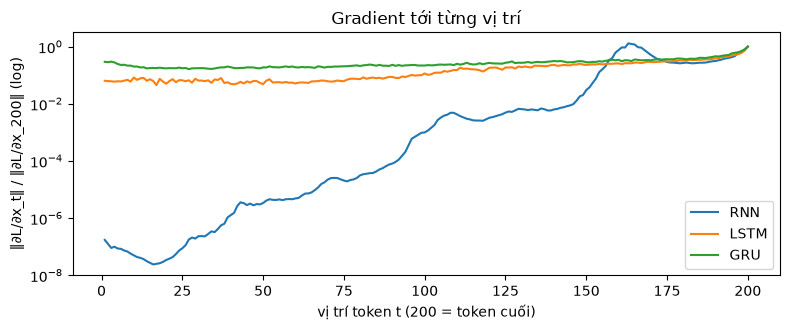

{'RNN': 'grad(t=1)/grad(t=200) = 1.74e-07, grad(t=100)/grad(t=200) = 9.98e-04', 'LSTM': 'grad(t=1)/grad(t=200) = 6.40e-02, grad(t=100)/grad(t=200) = 1.16e-01', 'GRU': 'grad(t=1)/grad(t=200) = 2.94e-01, grad(t=100)/grad(t=200) = 2.19e-01'}


In [11]:
long_idx = [i for i, t in enumerate(tok["val"]) if len(t) >= 200][:512]
Xl, ll = to_tensor([tok["val"][i] for i in long_idx], 200)
yl = torch.tensor(y["val"][long_idx], dtype=torch.float32, device=device)
grad_prof = {}
for name in ("RNN", "LSTM", "GRU"):
    m = store[name]["model"]; m.train()                   # cuDNN chỉ backward được ở train mode
    m.drop.p, keep_p = 0.0, m.drop.p
    e = m.emb(Xl.to(device)).detach().requires_grad_(True)
    nn.BCEWithLogitsLoss()(m(Xl.to(device), ll.to(device), embedded=e), yl).backward()
    grad_prof[name] = e.grad.norm(dim=-1).mean(0).cpu().numpy()
    m.drop.p = keep_p; m.eval()
fig, ax = plt.subplots(figsize=(8, 3.4))
for name, g in grad_prof.items():
    ax.semilogy(np.arange(1, 201), g / g[-1], label=name)
ax.set_xlabel("vị trí token t (200 = token cuối)"); ax.set_ylabel("‖∂L/∂x_t‖ / ‖∂L/∂x_200‖ (log)"); ax.set_title("Gradient tới từng vị trí"); ax.legend()
plt.tight_layout(); plt.savefig("gradient_position.png", dpi=150); plt.show()
print({n: f"grad(t=1)/grad(t=200) = {g[0] / g[-1]:.2e}, grad(t=100)/grad(t=200) = {g[99] / g[-1]:.2e}" for n, g in grad_prof.items()})

## Error analysis — model tốt nhất trên test

In [12]:
rec = [r for r in results if r["model"] in ("RNN", "LSTM", "GRU")]
BEST = max(rec, key=lambda r: r["f1"])["model"]
print("Model phân tích:", BEST)
pb = store[BEST]["prob"]; pl = store["Logistic Regression"]["prob"]
ea = pd.DataFrame({"text": test_df.text.str.replace("<br />", " "), "true": y["test"], "P(pos)": pb, "P(pos) TF-IDF": pl,
                   "length": [len(t) for t in tok["test"]]})
ea["pred"] = (ea["P(pos)"] > 0.5).astype(int); ea["truncated"] = ea.length > 200
lab = {0: "negative", 1: "positive"}
cm = confusion_matrix(ea.true, ea.pred); print("Confusion matrix (hàng = thật neg/pos, cột = dự đoán neg/pos):\n", cm)
print("Accuracy theo độ dài:", ea.groupby(pd.cut(ea.length, [0, 100, 200, 400, 3000]))[["pred", "true"]].apply(lambda d: (d.pred == d.true).mean()).round(4).to_dict())
neg_words = re.compile(r"\b(not|no|never|n't|nothing|isn't|wasn't|don't|didn't)\b")
contrast = re.compile(r"\b(but|however|although|though|yet)\b")
ea["negation"] = ea.text.str.lower().str.count(neg_words.pattern); ea["contrast"] = ea.text.str.lower().str.contains(contrast.pattern)
wrong = ea[ea.pred != ea.true]
print(f"Lỗi: {len(wrong)}; tỉ lệ lỗi bị truncate (>200 token): {wrong.truncated.mean():.1%} so với toàn test {ea.truncated.mean():.1%}")
print(f"Trong các lỗi của {BEST}, TF-IDF + LR đoán đúng {( (wrong['P(pos) TF-IDF'] > 0.5) == wrong.true).mean():.1%}")
pd.set_option("display.max_colwidth", 260)
show_cols = ["true", "pred", "P(pos)", "P(pos) TF-IDF", "length", "negation", "contrast", "text"]
rs = np.random.RandomState(7)
print("\nĐÚNG (ngẫu nhiên):"); display(ea[ea.pred == ea.true].sample(3, random_state=7)[show_cols].assign(text=lambda d: d.text.str[:260]))
print("\nSAI — tự tin nhất (|P−0.5| lớn):"); display(wrong.assign(m=(wrong["P(pos)"] - 0.5).abs()).sort_values("m", ascending=False).head(4)[show_cols].assign(text=lambda d: d.text.str[:260]))
print("\nSAI — review dài bị truncate:"); display(wrong[wrong.truncated].sample(3, random_state=1)[show_cols].assign(text=lambda d: d.text.str[:260]))

Model phân tích: GRU
Confusion matrix (hàng = thật neg/pos, cột = dự đoán neg/pos):
 [[11125  1375]
 [ 2821  9679]]
Accuracy theo độ dài: {Interval(0, 100, closed='right'): 0.8691, Interval(100, 200, closed='right'): 0.8674, Interval(200, 400, closed='right'): 0.7976, Interval(400, 3000, closed='right'): 0.7387}


Lỗi: 4196; tỉ lệ lỗi bị truncate (>200 token): 53.0% so với toàn test 40.3%
Trong các lỗi của GRU, TF-IDF + LR đoán đúng 57.2%

ĐÚNG (ngẫu nhiên):


,true,pred,P(pos),P(pos) TF-IDF,length,negation,contrast,text
7218,0,0,0.085981,0.305510,125,1,False,"This was by far the worst movie I've ever seen. And thats compared to Alexander, Fortress 2 and The new world. I should go back to blockbuster and ask for my money back along with compensation as it was a truly traumatic experience. For the first ten minu..."
16225,1,1,0.976814,0.770248,239,0,False,"I viewed the original Outer Limits in real time, when first broadcast and have since viewed the entire original series again and again in re-runs and complete on DVD. I find the New Outer Limits WELL MORE than just a remake of old retread episodes, as some..."
2803,0,0,0.104001,0.250426,86,1,True,"Amnesiac women who remove their clothes at the drop of a hat (or a blouse?) are about the only stand-out points in a film that is otherwise slow and aimless. Although the basic premise of the story offers a wealth of possibilities, they are never developed..."



SAI — tự tin nhất (|P−0.5| lớn):


,true,pred,P(pos),P(pos) TF-IDF,length,negation,contrast,text
12061,0,1,0.992580,0.988092,81,1,True,"This movie was pure genius. John Waters is brilliant. It is hilarious and I am not sick of it even after seeing it about 20 times since I bought it a few months ago. The acting is great, although Ricki Lake could have been better. And Johnny Depp is magnif..."
23867,1,0,0.007611,0.176735,398,6,True,"I want to preface this review by saying that I have no idea what ""Begotten"" is truly about. All I really know is that in the beginning God kills himself, in turn birthing Mother Earth, who proceeds to impregnate herself with God's semen. She then births a ..."
18896,1,0,0.007826,0.089328,189,3,True,"Miles O'Keeffe once again assumes the role of the mighty Ator in this the first sequel to the original film. What can I say? - This pretty much represents B-Movie Nirvana! The plot is ludicrous, the script is terrible, the acting is hammy throughout, th..."
19816,1,0,0.008130,0.165865,219,3,True,"Okay, I'll say it. This movie made me laugh so hard that it hurt. This statement may offend some of you who may think that this movie is nothing more than a waste of film. But the thing that most people don't get is that this movie was intended to be bad a..."



SAI — review dài bị truncate:


,true,pred,P(pos),P(pos) TF-IDF,length,negation,contrast,text
19227,1,0,0.041954,0.515438,576,1,True,"To the guy who hatched the idea for Lifeforce I have one thing to say: Thank you, sir! Lifeforce combines the big-budget sci-fi pomp of Star Trek: The Motion Picture with the cheap horror thrills of Phantasm and tops it all off with t-ts-- and some real me..."
13602,1,0,0.334279,0.822216,260,4,True,mondovino is a moving and rewarding documentary. in the world of wine there is a huge different between the big winery and the small one. it's not just about size of of your vineyard but also the amount of money and power you have. if you have enough money...
17238,1,0,0.135253,0.800516,606,12,True,"First they came for the Communists, and I didn't speak up, because I wasn't a Communist. Then they came for the Jews, and I didn't speak up, because I wasn't a Jew. Then they came for the Catholics, and I didn't speak up, because I was a Protestant. Then t..."


In [13]:
def show_full(i, n=1500):
    r = ea.loc[i]
    print(f"[{i}] true={lab[r.true]} pred={lab[r.pred]} P(pos)={r['P(pos)']:.3f} TF-IDF={r['P(pos) TF-IDF']:.3f} len={r.length}")
    print("   200 token đầu:", " ".join(tok["test"][i][:200])[:n]); print("   ...30 token cuối:", " ".join(tok["test"][i][-30:])); print()
picked = list(wrong.assign(m=(wrong["P(pos)"] - 0.5).abs()).sort_values("m", ascending=False).head(4).index) + list(wrong[wrong.truncated].sample(3, random_state=1).index)
for i in picked:
    show_full(i, 700)

[12061] true=negative pred=positive P(pos)=0.993 TF-IDF=0.988 len=81
   200 token đầu: this movie was pure genius john waters is brilliant it is hilarious and i am not sick of it even after seeing it about 20 times since i bought it a few months ago the acting is great although ricki lake could have been better and johnny depp is magnificent he is such a beautiful man and a very talented actor and seeing most of johnny's movies this is probably my favorite i give it 9 5 10 rent it today
   ...30 token cuối: is such a beautiful man and a very talented actor and seeing most of johnny's movies this is probably my favorite i give it 9 5 10 rent it today

[23867] true=positive pred=negative P(pos)=0.008 TF-IDF=0.177 len=398
   200 token đầu: i want to preface this review by saying that i have no idea what begotten is truly about all i really know is that in the beginning god kills himself in turn birthing mother earth who proceeds to impregnate herself with god's semen she then births a son

## Application — Sentiment classifier hoàn chỉnh
`raw review → tokenizer → vocabulary → token IDs → padding/truncation → embedding → LSTM/GRU → linear → sentiment`.
Giải thích bằng **occlusion**: bỏ từng token và đo P(pos) thay đổi bao nhiêu (token làm P thay đổi nhiều nhất = ảnh hưởng nhiều nhất).

In [14]:
def classify(text, name=BEST, max_len=200):
    t = tokenize(text)
    X, l = to_tensor([t], max_len); p = float(predict_proba(store[name]["model"], X, l)[0])
    t_ = t[:max_len]
    occl = [t_[:i] + t_[i + 1:] for i in range(len(t_))] if len(t_) > 1 else []
    po = prob_texts(name, occl) if occl else np.array([])
    infl = sorted(zip(t_, p - po), key=lambda x: -abs(x[1]))[:4]
    return {"sentiment": "Positive" if p > 0.5 else "Negative", "P(pos)": round(p, 3), "tokens": len(t),
            "most influential (ΔP khi bỏ token)": ", ".join(f"{w} {d:+.2f}" for w, d in infl)}

long_review = test_df.text[ea[(ea.length > 350) & (ea.pred == ea.true) & (ea.true == 1)].index[0]]
APP = {"short": "I really enjoyed this movie.",
       "long": long_review.replace("<br />", " "),
       "negation": "This is not a good movie and I did not enjoy it at all.",
       "negation 2": "Not bad at all, I was never bored.",
       "contrast": "I thought the movie would be terrible, but it was surprisingly good.",
       "contrast 2": "The acting was wonderful, but the story was boring and the ending was awful.",
       "expected-bad": "I expected the movie to be bad, but it was actually wonderful."}
app_rows = []
for kind, text in APP.items():
    for name in (BEST, "RNN"):
        app_rows.append({"type": kind, "model": name, "text": text[:110] + ("…" if len(text) > 110 else ""), **classify(text, name)})
app_df = pd.DataFrame(app_rows)
display(app_df)

,type,model,text,sentiment,P(pos),tokens,most influential (ΔP khi bỏ token)
0,short,GRU,I really enjoyed this movie.,Positive,0.682,5,"enjoyed +0.20, i +0.04, movie +0.02, this -0.00"
1,short,RNN,I really enjoyed this movie.,Positive,0.718,5,"i +0.29, this -0.18, really -0.12, movie -0.11"
2,long,GRU,"CONTAINS ""SPOILER"" INFORMATION. Watch this director's other film, ""Earth"", at some point. It's a better film, …",Positive,0.934,366,"herself +0.03, unable -0.02, is -0.01, matriarch +0.01"
3,long,RNN,"CONTAINS ""SPOILER"" INFORMATION. Watch this director's other film, ""Earth"", at some point. It's a better film, …",Positive,0.884,366,"due +0.08, a +0.07, to +0.07, herself +0.04"
4,negation,GRU,This is not a good movie and I did not enjoy it at all.,Positive,0.590,14,"not -0.26, not -0.20, enjoy +0.15, good +0.11"
5,negation,RNN,This is not a good movie and I did not enjoy it at all.,Negative,0.380,14,"all -0.44, not -0.38, not -0.28, enjoy +0.27"
6,negation 2,GRU,"Not bad at all, I was never bored.",Negative,0.216,8,"bad -0.14, bored -0.10, never +0.08, not +0.07"
7,negation 2,RNN,"Not bad at all, I was never bored.",Negative,0.084,8,"bored -0.09, bad -0.06, was -0.04, never +0.02"
8,contrast,GRU,"I thought the movie would be terrible, but it was surprisingly good.",Positive,0.573,12,"terrible -0.30, good +0.19, surprisingly +0.16, it +0.10"
9,contrast,RNN,"I thought the movie would be terrible, but it was surprisingly good.",Positive,0.557,12,"surprisingly +0.33, terrible -0.32, good +0.22, i +0.22"


In [15]:
res = pd.DataFrame(results)
res.round(4).to_csv("results.csv", index=False)
print("Đã ghi results.csv"); display(res[["model", "max_length", "truncation", "params", "best epoch", "train time (s)", "peak GPU mem (MB)", "accuracy", "precision", "recall", "f1"]].round(4))

Đã ghi results.csv


,model,max_length,truncation,params,best epoch,train time (s),peak GPU mem (MB),accuracy,precision,recall,f1
0,Logistic Regression,full,NaN,40791,-,7.1463,NaN,0.8882,0.8881,0.8885,0.8883
1,Logistic Regression (200 tokens đầu),200,NaN,34395,-,5.7810,NaN,0.8621,0.8634,0.8603,0.8619
2,RNN,200,head,2529769,6,37.3231,229.1938,0.7408,0.7274,0.7702,0.7482
3,LSTM,200,head,2618089,4,42.3080,373.9956,0.8156,0.8291,0.7950,0.8117
4,GRU,200,head,2588649,3,40.3797,351.1724,0.8322,0.8756,0.7743,0.8219
5,LSTM len 50,50,head,2618089,4,17.5315,220.0962,0.7457,0.7347,0.7691,0.7515
6,LSTM len 100,100,head,2618089,5,25.5582,318.5342,0.7901,0.8035,0.7679,0.7853
7,LSTM len 400,400,head,2618089,4,69.9353,568.3882,0.8492,0.8605,0.8335,0.8468
8,LSTM len 100 (tail),100,tail,2618089,3,24.7221,358.4854,0.8288,0.8333,0.8220,0.8276
